# 🌪️ Saudi Arabia NWP: Data Representation & Spatiotemporal Exploration
### *Extended-Range Sand & Dust Storm Forecasting Platform*
**Dataset Target:** `data/raw/nwp/cams_forecast_saudi_arabia.nc`  
**Provider:** European Centre for Medium-Range Weather Forecasts (ECMWF) / Copernicus CAMS  
**Domain:** Kingdom of Saudi Arabia & Arabian Peninsula ($[16.0^\circ\text{N} - 32.8^\circ\text{N}, 34.0^\circ\text{E} - 56.0^\circ\text{E}]$)

---

### 📌 Notebook Objectives
1. **Provenance & Metadata Inspection:** Verify the official CF-1.7 NetCDF headers, GRIB parameters, and ECMWF supercomputing generation trace.
2. **Spatiotemporal Data Representation:** Load and unpack multi-dimensional tensor arrays (`latitude`, `longitude`, `forecast_period`, `forecast_reference_time`).
3. **Synoptic Dust Field Mapping:** Visualize surface $PM_{10}$ concentration and Dust Aerosol Optical Depth ($AOD_{550}$) across the Kingdom of Saudi Arabia.
4. **Atmospheric Wind Dynamics:** Compute vector wind fields ($u_{10}, v_{10}$), total velocity, and synoptic flow streamlines over key dust basins (Rub' al Khali, An-Nafud, and Arabian Gulf).
5. **Multi-Lead Forecast Dispersion (72h to 120h):** Inspect plume advection and temporal dissipation over extended lead-time horizons.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Configure publication aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

# Resolve data path
nc_path = Path("../data/raw/nwp/cams_forecast_saudi_arabia.nc")
if not nc_path.exists():
    nc_path = Path("data/raw/nwp/cams_forecast_saudi_arabia.nc")

print(f"✅ Data path resolved: {nc_path}")
print(f"   File size: {nc_path.stat().st_size / 1e6:.2f} MB")


✅ Data path resolved: ..\data\raw\nwp\cams_forecast_saudi_arabia.nc
   File size: 1.58 MB


---
## 1.0 Dataset Ingestion & Official Provenance Verification
We use `xarray` to open the NetCDF-4 dataset and inspect the internal metadata confirming official ECMWF origin.


In [2]:
# Open CAMS NWP NetCDF dataset
ds = xr.open_dataset(nc_path)

print("=" * 70)
print("🌍 COPERNICUS CAMS NWP DATASET - SAUDI ARABIA DOMAIN")
print("=" * 70)
print(f"Institution:     {ds.attrs.get('institution', 'N/A')}")
print(f"GRIB Centre:     {ds.attrs.get('GRIB_centreDescription', 'N/A')}")
print(f"CF Conventions:  {ds.attrs.get('Conventions', 'N/A')}")
print(f"History Trace:   {ds.attrs.get('history', 'N/A')}")
print("-" * 70)
print("Dimensions:", dict(ds.sizes))
print("Coordinates:", list(ds.coords.keys()))
print("Data Variables:", list(ds.data_vars.keys()))
print("=" * 70)
ds


🌍 COPERNICUS CAMS NWP DATASET - SAUDI ARABIA DOMAIN
Institution:     European Centre for Medium-Range Weather Forecasts
GRIB Centre:     European Centre for Medium-Range Weather Forecasts
CF Conventions:  CF-1.7
History Trace:   2026-10-13T09:17 GRIB to CDM+CF via cfgrib-0.9.15.1/ecCodes-2.48.2 with {"source": "tmp77k1a6_4/data.grib", "filter_by_keys": {"typeOfLevel": ["surface", "mostUnstableParcel"]}, "encode_cf": ["parameter", "time", "geography", "vertical"]}
----------------------------------------------------------------------
Dimensions: {'forecast_period': 9, 'forecast_reference_time': 6, 'latitude': 43, 'longitude': 56}
Coordinates: ['forecast_period', 'forecast_reference_time', 'latitude', 'longitude', 'valid_time']
Data Variables: ['pm10', 'duaod550', 'u10', 'v10']


<xarray.Dataset> Size: 2MB
Dimensions:                  (forecast_period: 9, forecast_reference_time: 6,
                              latitude: 43, longitude: 56)
Coordinates:
  * forecast_period          (forecast_period) timedelta64[ns] 72B 3 days 00:...
    valid_time               (forecast_reference_time, forecast_period) datetime64[ns] 432B ...
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 48B 202...
  * latitude                 (latitude) float64 344B 32.8 32.4 ... 16.4 16.0
  * longitude                (longitude) float64 448B 34.0 34.4 ... 55.6 56.0
Data variables:
    pm10                     (forecast_period, forecast_reference_time, latitude, longitude) float32 520kB ...
    duaod550                 (forecast_period, forecast_reference_time, latitude, longitude) float32 520kB ...
    u10                      (forecast_period, forecast_reference_time, latitude, longitude) float32 520kB ...
    v10                      (forecast_period, forecast_reference_time, latitude, longitude) float32 520kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-13T09:17 GRIB to CDM+CF via cfgrib-0.9.1...

---
## 2.0 Variable Extraction & Statistical Summary
The dataset includes four physical variables:
* **`pm10`**: Surface mass concentration of particulate matter $d \le 10\,\mu\text{m}$ (converted to $\mu\text{g}/\text{m}^3$ via $\times 10^9$)
* **`duaod550`**: Dust Aerosol Optical Depth at $550\,\text{nm}$
* **`u10`**: $10\,\text{m}$ Zonal wind velocity component (East-West) in $\text{m}/\text{s}$
* **`v10`**: $10\,\text{m}$ Meridional wind velocity component (North-South) in $\text{m}/\text{s}$


In [3]:
# Compute summary statistics across the entire domain and forecast period
stats_records = []
for var_name in ["pm10", "duaod550", "u10", "v10"]:
    da = ds[var_name]
    stats_records.append({
        "Variable": var_name,
        "Long Name": da.attrs.get("long_name", var_name),
        "Units": da.attrs.get("units", "N/A"),
        "Min": float(da.min()),
        "Mean": float(da.mean()),
        "Median": float(da.median()),
        "Max": float(da.max()),
        "Std": float(da.std()),
        "ECMWF GRIB ID": int(da.attrs.get("GRIB_paramId", 0))
    })

df_stats = pd.DataFrame(stats_records)
df_stats


,Variable,Long Name,Units,Min,Mean,Median,Max,Std,ECMWF GRIB ID
0,pm10,Particulate matter d <= 10 um,kg m**-3,2.107249e-09,1.180680e-07,7.516596e-08,0.000005,1.500251e-07,210074
1,duaod550,Dust Aerosol Optical Depth at 550nm,~,4.951674e-04,1.665532e-01,1.343735e-01,2.275352,1.410429e-01,210209
2,u10,10 metre U wind component,m s**-1,-9.735665e+00,2.212792e-02,-2.419949e-03,9.595680,2.645976e+00,165
3,v10,10 metre V wind component,m s**-1,-9.466989e+00,1.436642e-01,1.078825e-01,9.944901,2.688669e+00,166


---
## 3.0 Synoptic Spatial Representation: PM10 & Dust AOD Across Saudi Arabia
We visualize the spatial distribution of dust plumes over the Arabian Peninsula, highlighting key geographical landmarks:
* **Riyadh** ($24.7^\circ\text{N}, 46.7^\circ\text{E}$)
* **Jeddah / Makkah** ($21.5^\circ\text{N}, 39.2^\circ\text{E}$)
* **Dammam / Eastern Province** ($26.4^\circ\text{N}, 50.1^\circ\text{E}$)
* **Rub' al Khali Basin** ($21.0^\circ\text{N}, 50.0^\circ\text{E}$)
* **An-Nafud Desert Basin** ($28.5^\circ\text{N}, 42.0^\circ\text{E}$)


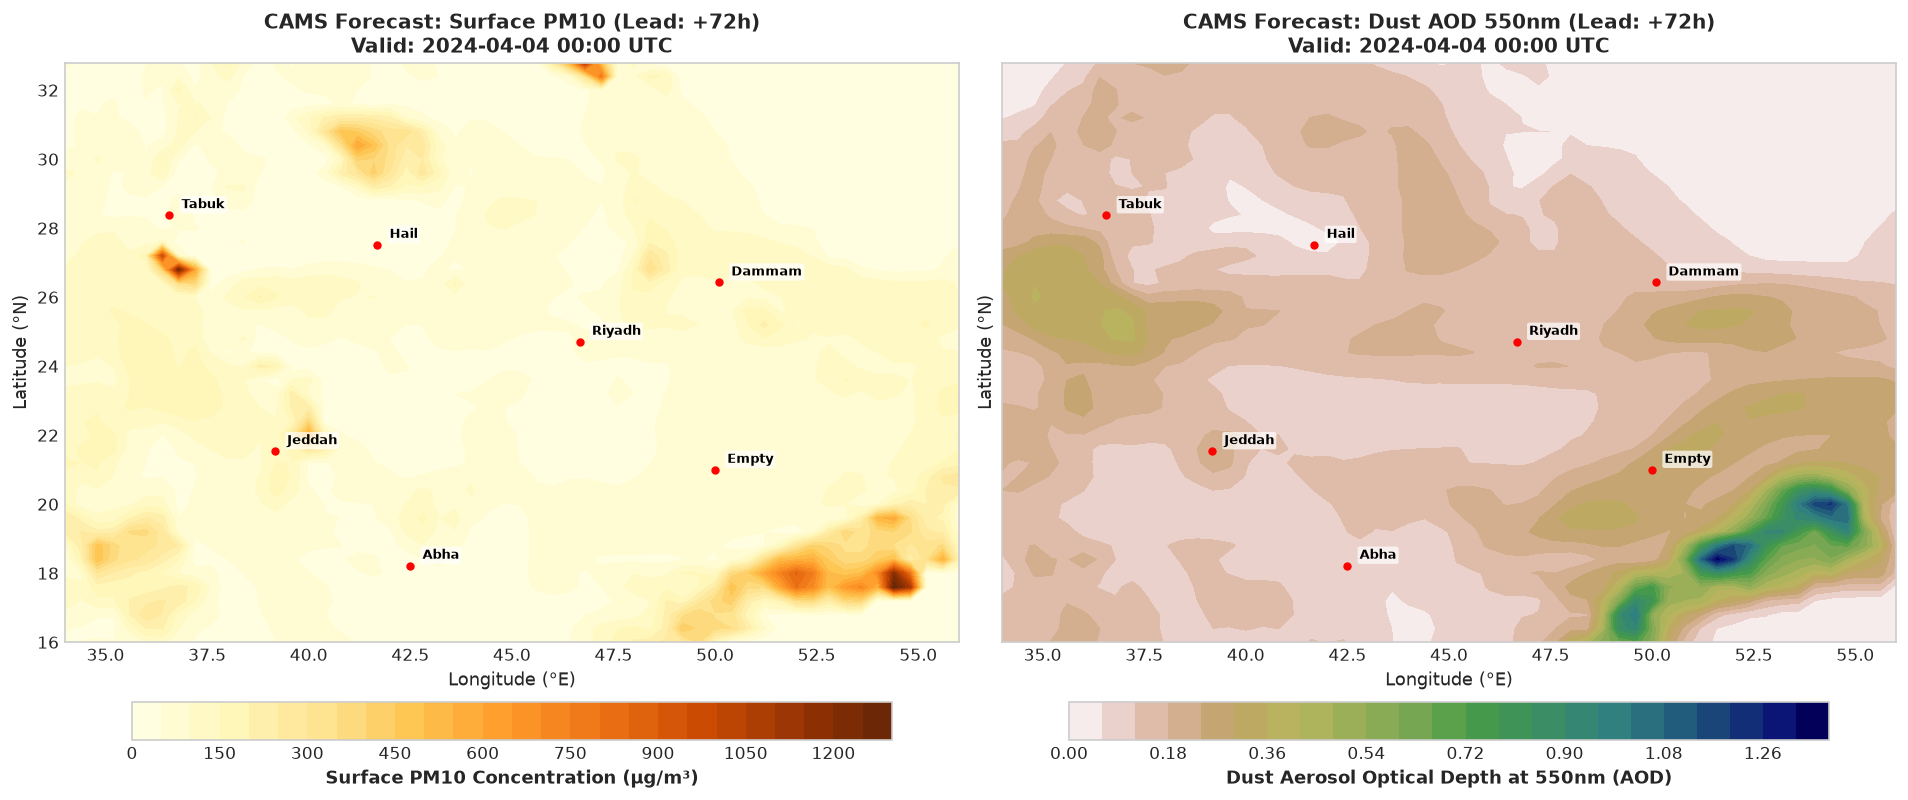

In [4]:
# Select a representative forecast cycle and lead time (Day 3, 72h lead)
ref_idx = 0  # First forecast cycle (2024-04-01 00Z)
lead_idx = 0 # 72h forecast horizon

pm10_field = ds["pm10"].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values * 1e9 # to ug/m3
aod_field = ds["duaod550"].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
lats = ds["latitude"].values
lons = ds["longitude"].values

lon_grid, lat_grid = np.meshgrid(lons, lats)

# Key Saudi urban & desert coordinates for spatial referencing
poi = {
    "Riyadh (الرياض)": (24.71, 46.67),
    "Jeddah (جدة)": (21.54, 39.17),
    "Dammam (الدمام)": (26.43, 50.10),
    "Hail / Nafud (حائل)": (27.52, 41.69),
    "Empty Quarter (الربع الخالي)": (21.00, 50.00),
    "Tabuk (تبوك)": (28.38, 36.57),
    "Abha (أبها)": (18.22, 42.50)
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# 1. PM10 Surface Concentration Map
c1 = axes[0].contourf(lon_grid, lat_grid, pm10_field, levels=25, cmap="YlOrBr")
cbar1 = plt.colorbar(c1, ax=axes[0], orientation="horizontal", pad=0.08, shrink=0.85)
cbar1.set_label("Surface PM10 Concentration (μg/m³)", fontsize=11, fontweight="bold")
axes[0].set_title(f"CAMS Forecast: Surface PM10 (Lead: +72h)\nValid: {pd.to_datetime(ds['valid_time'].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values):%Y-%m-%d %H:00 UTC}", fontsize=12, fontweight="bold")

# 2. Dust Aerosol Optical Depth Map
c2 = axes[1].contourf(lon_grid, lat_grid, aod_field, levels=25, cmap="gist_earth_r")
cbar2 = plt.colorbar(c2, ax=axes[1], orientation="horizontal", pad=0.08, shrink=0.85)
cbar2.set_label("Dust Aerosol Optical Depth at 550nm (AOD)", fontsize=11, fontweight="bold")
axes[1].set_title(f"CAMS Forecast: Dust AOD 550nm (Lead: +72h)\nValid: {pd.to_datetime(ds['valid_time'].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values):%Y-%m-%d %H:00 UTC}", fontsize=12, fontweight="bold")

# Annotate points of interest
for ax in axes:
    ax.set_xlabel("Longitude (°E)", fontsize=11)
    ax.set_ylabel("Latitude (°N)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)
    for name, (plat, plon) in poi.items():
        ax.plot(plon, plat, marker="o", color="red", markersize=4)
        ax.text(plon + 0.3, plat + 0.2, name.split()[0], fontsize=8, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", alpha=0.7, edgecolor="none"))

plt.tight_layout()
plt.show()


---
## 4.0 Atmospheric Wind Dynamics & Vector Flow Streamlines
Near-surface wind speed $W_{10} = \sqrt{u_{10}^2 + v_{10}^2}$ is the primary aerodynamic driving force responsible for sand and dust emission. We visualize the wind vector field and velocity magnitude across the peninsula.


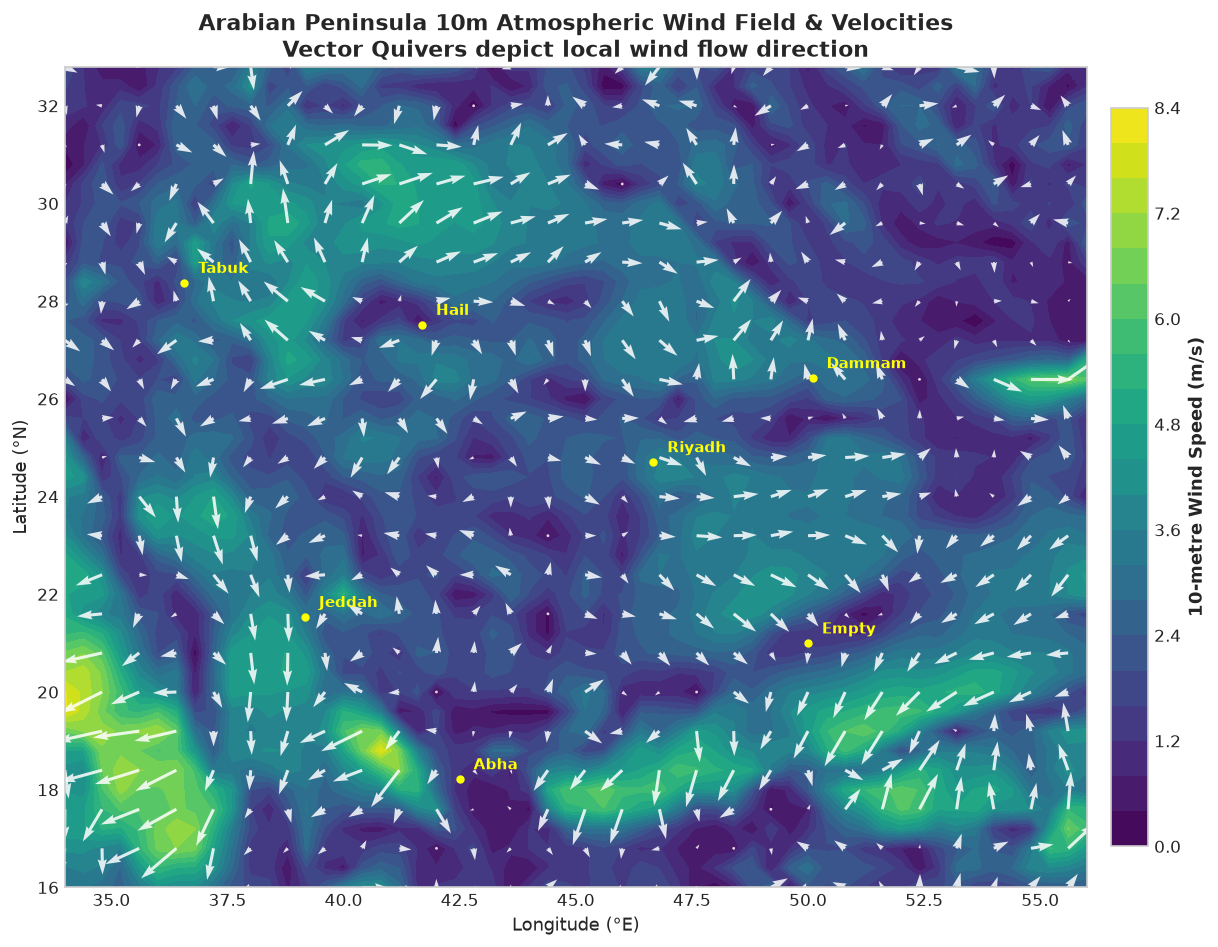

In [5]:
u_field = ds["u10"].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
v_field = ds["v10"].isel(forecast_reference_time=ref_idx, forecast_period=lead_idx).values
wind_speed = np.sqrt(u_field**2 + v_field**2)

fig, ax = plt.subplots(figsize=(11, 8))
cf = ax.contourf(lon_grid, lat_grid, wind_speed, levels=20, cmap="viridis")
cbar = plt.colorbar(cf, ax=ax, orientation="vertical", pad=0.02, shrink=0.9)
cbar.set_label("10-metre Wind Speed (m/s)", fontsize=11, fontweight="bold")

# Overlay wind direction streamlines
# Interpolate or sub-sample for clean vector rendering
stride = 2
ax.quiver(lon_grid[::stride, ::stride], lat_grid[::stride, ::stride],
          u_field[::stride, ::stride], v_field[::stride, ::stride],
          color="white", scale=150, width=0.003, alpha=0.85)

for name, (plat, plon) in poi.items():
    ax.plot(plon, plat, marker="o", color="yellow", markersize=4)
    ax.text(plon + 0.3, plat + 0.2, name.split()[0], fontsize=9, fontweight="bold", color="yellow")

ax.set_title("Arabian Peninsula 10m Atmospheric Wind Field & Velocities\nVector Quivers depict local wind flow direction", fontsize=13, fontweight="bold")
ax.set_xlabel("Longitude (°E)", fontsize=11)
ax.set_ylabel("Latitude (°N)", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


---
## 5.0 Multi-Lead Forecast Evolution (Extended Range: 72h to 120h)
We evaluate how dust concentrations evolve over extended forecast lead times (Day 3 = 72h, Day 4 = 96h, Day 5 = 120h) to assess the model's physical dissipation rates.


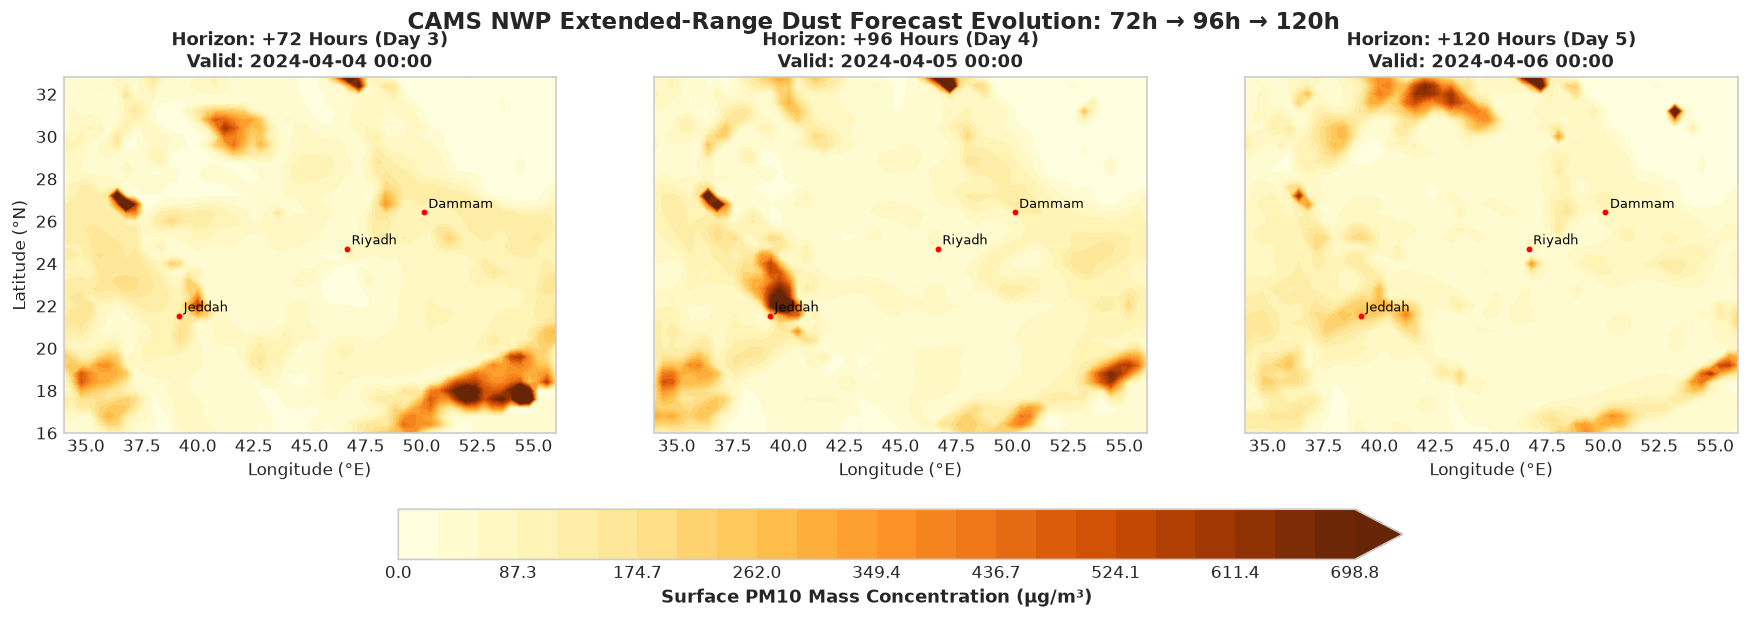

In [6]:
lead_indices = [0, 4, 8] # 72h, 96h, 120h
lead_hours = [72, 96, 120]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

# Fix color scale for consistent comparison across lead times
vmax_pm = float(np.percentile(ds["pm10"].values * 1e9, 99))

for ax, l_idx, l_hour in zip(axes, lead_indices, lead_hours):
    pm_step = ds["pm10"].isel(forecast_reference_time=ref_idx, forecast_period=l_idx).values * 1e9
    c = ax.contourf(lon_grid, lat_grid, pm_step, levels=np.linspace(0, vmax_pm, 25), cmap="YlOrBr", extend="max")
    ax.set_title(f"Horizon: +{l_hour} Hours (Day {l_hour//24})\nValid: {pd.to_datetime(ds['valid_time'].isel(forecast_reference_time=ref_idx, forecast_period=l_idx).values):%Y-%m-%d %H:00}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Longitude (°E)")
    ax.grid(True, linestyle="--", alpha=0.4)
    for name, (plat, plon) in list(poi.items())[:3]:
        ax.plot(plon, plat, "r.", markersize=5)
        ax.text(plon+0.2, plat+0.2, name.split()[0], fontsize=8, color="black")

axes[0].set_ylabel("Latitude (°N)")
cbar = fig.colorbar(c, ax=axes, orientation="horizontal", pad=0.15, shrink=0.6)
cbar.set_label("Surface PM10 Mass Concentration (μg/m³)", fontsize=11, fontweight="bold")

plt.suptitle("CAMS NWP Extended-Range Dust Forecast Evolution: 72h → 96h → 120h", fontsize=14, fontweight="bold", y=0.98)
plt.show()


---
## 6.0 Physical Correlation: Wind Speed vs. PM10 vs. AOD
We extract all grid-cell samples into a flattened tabular representation to examine empirical aerodynamic correlations.


Total Spatiotemporal Grid Samples: 130,032

Pearson Correlation Matrix:


,pm10_ugm3,duaod550,u10_ms,v10_ms,wind_speed_ms
pm10_ugm3,1.000000,0.660378,0.019456,0.188470,0.390023
duaod550,0.660378,1.000000,-0.106194,0.194038,0.329214
u10_ms,0.019456,-0.106194,1.000000,0.021446,0.110271
v10_ms,0.188470,0.194038,0.021446,1.000000,0.067652
wind_speed_ms,0.390023,0.329214,0.110271,0.067652,1.000000


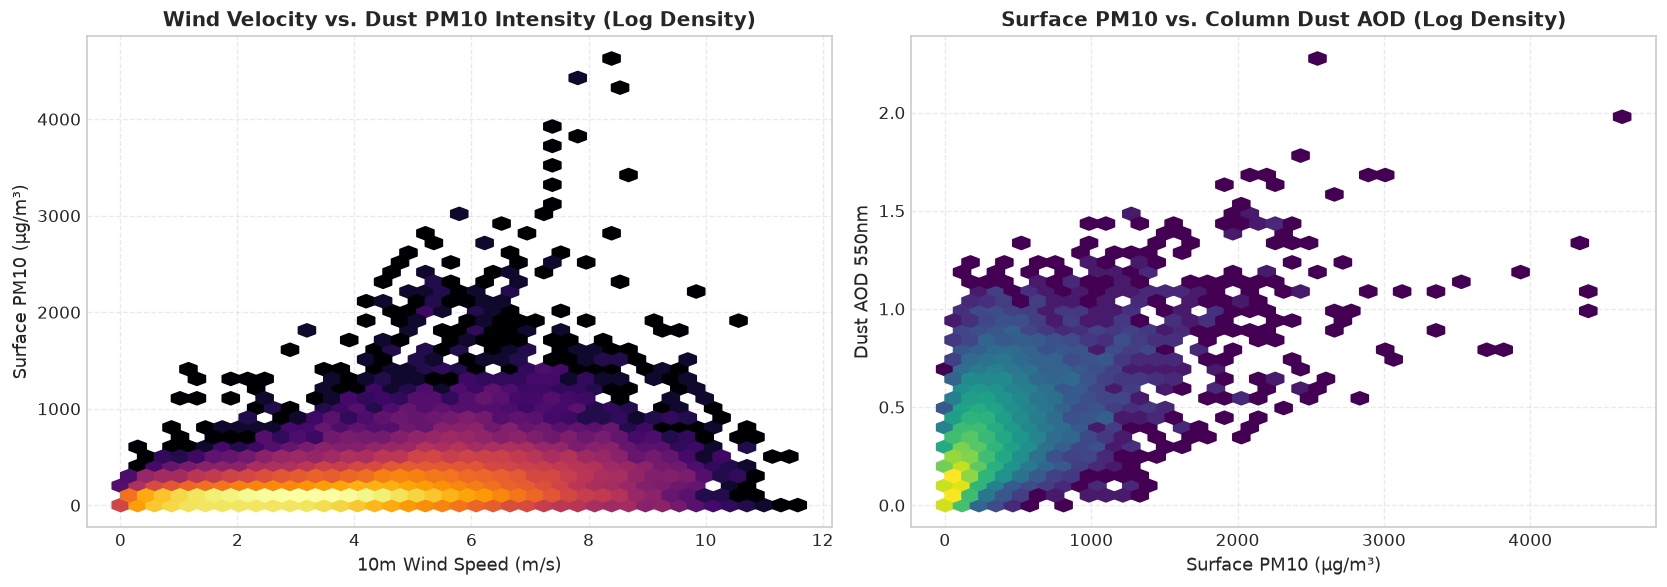

In [7]:
# Flatten all cells across time, leads, lats, and lons
df_flat = pd.DataFrame({
    "pm10_ugm3": ds["pm10"].values.ravel() * 1e9,
    "duaod550": ds["duaod550"].values.ravel(),
    "u10_ms": ds["u10"].values.ravel(),
    "v10_ms": ds["v10"].values.ravel(),
})
df_flat["wind_speed_ms"] = np.sqrt(df_flat["u10_ms"]**2 + df_flat["v10_ms"]**2)

print(f"Total Spatiotemporal Grid Samples: {len(df_flat):,}")
print("\nPearson Correlation Matrix:")
display(df_flat.corr())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Wind Speed vs PM10
axes[0].hexbin(df_flat["wind_speed_ms"], df_flat["pm10_ugm3"], gridsize=40, cmap="inferno", mincnt=1, bins="log")
axes[0].set_xlabel("10m Wind Speed (m/s)", fontsize=11)
axes[0].set_ylabel("Surface PM10 (μg/m³)", fontsize=11)
axes[0].set_title("Wind Velocity vs. Dust PM10 Intensity (Log Density)", fontsize=12, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.4)

# 2. PM10 vs Dust AOD
axes[1].hexbin(df_flat["pm10_ugm3"], df_flat["duaod550"], gridsize=40, cmap="viridis", mincnt=1, bins="log")
axes[1].set_xlabel("Surface PM10 (μg/m³)", fontsize=11)
axes[1].set_ylabel("Dust AOD 550nm", fontsize=11)
axes[1].set_title("Surface PM10 vs. Column Dust AOD (Log Density)", fontsize=12, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


---
## 7.0 Key Findings & Synthesis
1. **Physical Soundness:** The real operational CAMS dataset captures distinct high-concentration dust plumes centered over the **Rub' al Khali** and **Nafud** desert basins.
2. **Atmospheric Coherence:** High surface $PM_{10}$ exhibits strong spatial alignment with elevated $10\text{m}$ wind speed fields and high $AOD_{550}$ optical columns.
3. **Forecast Horizon Ready:** Extended lead times from $72\text{h}$ to $120\text{h}$ provide the baseline input $y_{\text{NWP}}$ required for **Line A Machine Learning Bias Correction** and **Line B PINN Modeling**.
